# Broad cohort: champion proficiency versus matchup, before and after personalization

**Question:** When does recorded champion proficiency outweigh a better matchup, and how does accounting for the individual player change the recommendation?

This notebook prepares the completed 300-player Bronze–Diamond cohort, builds externally defined A–J mastery-payoff groups, and specifies matched shared/grouped-experience hierarchical logistic models. It retains fitting controls, sampling diagnostics, held-out evaluation, model-based experience curves, and personalized recommendations. The Master cohort remains separate for a later comparison. There is no synergy analysis.

**Execution control:** `RUN_MODELING=False` prevents optimization, sampling, evaluation, and model-based recommendations. No Riot or LoLalytics collection is invoked. Prepared outputs retain all 5,706 played rows and 47,356 eligible alternatives.

Open [broad_rank_eda.ipynb](broad_rank_eda.ipynb) for descriptive tables, coverage figures, and all presentation plots. Each notebook has its own setup and can run independently.


## 1. Environment, pinned inputs, and fitting control

The original `python3` kernel resolves to `/opt/anaconda3/bin/python`. Its NumPy 2.5.4 is incompatible with installed compiled SciPy/matplotlib components. This run uses `.venv-modeling`, based on that interpreter with system packages, NumPy 1.26.4, pandas 2.2.3 and exact **pyro-ppl==1.9.2**. PyPI availability and dependency resolution were verified before installation. The base environment is unchanged.

Select **Riot modeling (.venv-modeling)**. The setup prints the actual interpreter and dependency versions. Preparation is executed with `RUN_MODELING=False` before smoke/full fitting. Smoke uses 2 sequential NUTS chains, 25 warmup + 25 draws on at most 24 training matches. Full retains 4 sequential chains, 600 warmup + 1,200 draws, target acceptance .9, depth 9 and one torch thread. No collection runs.

The source is `20261027T194148939685Z_3b8d192e`; metadata, source files and workbook hashes remain pinned.

For smoke only, mass-matrix adaptation is disabled because 25 warmup steps could not estimate its dense block reliably. Full fitting retains the original adapted mass matrix and settings. Dependency pins are saved in [requirements-modeling.txt](requirements-modeling.txt). To expose the project kernel when launching Jupyter, set `JUPYTER_PATH="$PWD/.venv-modeling/share/jupyter"` from the repository root, or select `.venv-modeling/bin/python` in your notebook editor.


In [1]:
from pathlib import Path
import sys, json, importlib, importlib.util
import numpy as np
import pandas as pd
from IPython.display import display, Image

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents]
    if (p / 'hlr_model/broad_rank_pipeline.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the repository root or hlr_model/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from hlr_model import broad_rank_modeling as modeling
importlib.reload(modeling)

RUN_MODELING = True
CONFIG = modeling.Config(profile='full')
print('Notebook interpreter:', sys.executable)
import importlib.metadata as metadata
DEPENDENCIES = {name: metadata.version(name) for name in (
    'numpy','pandas','scipy','scikit-learn','matplotlib','openpyxl','pyarrow','torch','pyro-ppl')}
assert DEPENDENCIES['pyro-ppl'] == '1.9.2', DEPENDENCIES
print('Dependencies:', DEPENDENCIES)
print('Fitting enabled:', RUN_MODELING)
print('Sampling profile:', CONFIG.profile, CONFIG.sampling)
print('Pyro installed in this notebook environment:', importlib.util.find_spec('pyro') is not None)
print('No collector or network request is used by this notebook.')

Notebook interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling/bin/python
Dependencies: {'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.13.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.9.2', 'openpyxl': '3.1.5', 'pyarrow': '17.0.0', 'torch': '2.15.0', 'pyro-ppl': '1.9.2'}
Fitting enabled: True
Sampling profile: full {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}
Pyro installed in this notebook environment: True
No collector or network request is used by this notebook.


## 2. Load the completed source

The source metadata report 28,876 published of 28,936 requested unique benchmarks, with 60 not published in verified tables. Availability is not equivalent to a failed request. Missing raw probabilities remain missing. The 100-game flag is reporting only.

Source row identifiers, benchmark evidence, raw/adjusted values, candidate mappings, and initial-history metadata remain intact. Raw Global exact-tier probability enters the model with an estimated slope; the derived tier-centered percentage is neither a probability nor a fixed logit offset.

In [2]:
bundle = modeling.load_source(PROJECT_ROOT, CONFIG)


## 3. Load the external workbook and derive A–J groups

The workbook contains **Data Intro**, **Easiest to Learn**, and **Best to Master**. Only the full **Best to Master** table's `Medium Mastery Win Rate` and `High Mastery Win Rate` define these groups. The source's ratio column is preserved and is **not** used instead of a difference.

Excel cells store probabilities and use percent formatting. Thus:

- `raw_gain_pp = 100 × (high_probability − medium_probability)`
- `grouping_score = max(0, raw_gain_pp)`
- J contains every usable row with score exactly zero.
- Positive scores are sorted descending; A–I use nine equal rank intervals. A tied block receives its mean zero-based rank r, then group index `min(8, floor(9*r/(N_positive−1)))`. A single positive row goes to A. Whole ties stay together; uneven/empty groups are reported.
- Unusable/missing rows stay Unclassified, including entries marked “low data.” There is no median imputation.

Stable IDs use the project's explicit Riot-name/display-alias registry, with the reviewed workbook name **Nunu & Willump → Nunu (20)**. Unknown/ambiguous names stop grouping rather than guessing.

The original workbook, all original rates, signed gains, clipped scores, classifications, row/sheet provenance, intro text, source URL, and hashes are preserved. The study uses patch **13.7**, mostly Gold, roughly equal EUW/NA/KR samples; high mastery means **100K+ mastery points**, medium 10K–100K. These are external grouping labels, not recorded-game counts or universal causal learning curves. Published gains never enter predicted probabilities.

In [3]:
groups, study_rows, study_metadata = modeling.load_groups(PROJECT_ROOT, CONFIG)


## 4. Audit pregame histories, preserve candidates, and freeze chronological partitions

Proficiency is **recorded prior champion games across all roles**. It is not lifetime experience. Initial histories contain up to 170 season-bounded games; they expand with earlier targets completed strictly before kickoff. This notebook independently reconstructs counts, the existing all-role main (most prior games; smallest champion ID breaks ties), historical Beta(1,1) WR, and same-role eligibility.

Alternatives are exactly previously played same-role champions, excluding the actual pick and known opponent. Each alternative gets its **own** prior counts and historical WR; it never receives the target outcome as a training label. At zero recorded champion games, Beta(1,1) WR = 0.5 is a historical prior assumption, not a filled external benchmark. The workbook's most-common-role column does not replace the player's target role.

Preserve the existing Master analysis dates for a later matched comparison:
- Train: kickoff before **2026-10-02 22:25:06.238 UTC**, with outcomes completed before that boundary.
- Validation: that boundary through **2026-10-05 01:32:18.312 UTC**, with outcomes completed before the test boundary.
- Final test: later kickoffs; no held-out refit or settings selection.
- All rows of a shared match stay together. Whole unfinished matches are purged at the corresponding boundary.

Earlier held-out games may update later pregame history after completion, but their outcomes never refit parameters or player effects. Neither specifications nor k are chosen using held-out outcomes. Both models use identical usable rows and partitions. Unclassified and sparse positive-count benchmarks are retained; exclusions and purged rows are explicitly reported.

In [4]:
prepared = modeling.prepare(bundle, groups, CONFIG)
tables = modeling.coverage_tables(prepared, groups)
assert prepared['played'].groupby('match_id').split.nunique().eq(1).all()
usable_counts = prepared['played'].loc[prepared['played'].usable_data].groupby('split').size()
assert usable_counts.reindex(['train','validation','test']).to_dict() == {'train':3907,'validation':852,'test':928}, usable_counts
display(tables['split_support'])


,split,rows,players,matches,usable_rows,included_rows
0,purged_train_boundary,6,6,6,6,0
1,purged_validation_boundary,11,11,11,11,0
2,test,929,152,926,928,928
3,train,3908,265,3893,3907,3907
4,validation,852,147,850,852,852


## 5. Versioned preparation, model configuration, and fit caches

Outputs are separate from collectors and Master analysis, under `hlr_model/data/analyses/broad_rank_mastery_v1/<version>/`. Identical pinned input/configuration/code reuses the verified preparation version; changed inputs or settings create a new version. Fitting caches individual completed chains inside that version. This lets an interrupted fit resume without overwriting other analyses.

The preparation manifest hashes all prepared outputs. Each model's fit manifest freezes the exact training design, observations, inference settings, backend version, seed, and model source. No fitted result is implied by a preparation manifest.

The existing helper reuses the verified preparation for the pinned inputs and unchanged settings. Coverage figures and descriptive tables are viewed in [broad_rank_eda.ipynb](broad_rank_eda.ipynb).


In [5]:
OUTPUT_PATH = modeling.prepare_outputs(
    PROJECT_ROOT, bundle, groups, study_rows, study_metadata, prepared, tables, CONFIG)
print('Analysis version:', OUTPUT_PATH.relative_to(PROJECT_ROOT))
if not (OUTPUT_PATH / 'execution_environment.json').exists():
    modeling.atomic_json(OUTPUT_PATH / 'execution_environment.json', dict(interpreter=sys.executable, dependencies=DEPENDENCIES))


Analysis version: hlr_model/data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939


## 6. Matched hierarchical logistic specifications

For observed training row i:

`logit P(win_i) = alpha + X_i beta + rank_i + role_i + champion_baseline_i + player_i + player_champion_i + b_group(i) × n_i/(n_i+k)`

X contains training-standardized **raw matchup probability**, **log1p(prior total games)**, and the selected champion's **all-role historical WR Beta(1,1)**. These retain the existing nonlinear tradeoff model's covariates. No external gain, clipped score, tier-centered percentage, current result, or future history is added.

**Shared:** one experience amplitude b. **Grouped:** the same model plus partially pooled A–J/Unclassified amplitude deviations. Both initially share one k across all groups, with the established log(k) ~ Normal(log 30, 1) prior and training-only estimation. There are no per-champion curve shapes or unnecessary rank/group interactions. J may have any fitted effect; Unclassified has one pooled fallback slope with uncertainty, not independent champion-specific curves.

Regularization: fixed continuous coefficients/intercept Normal(0,2); rank/role contrasts Normal(0,1); shared amplitude Normal(0,1); log player/champion scales Normal(log .3,.7); log player–champion scale Normal(log .15,.5); log group contrast scale Normal(log .3,.7). Latents are noncentered Normal(0,1). Bronze/top are fixed references; champion baselines and group deviations use orthonormal zero-sum contrasts. Player and player–champion effects have proper zero-mean population distributions.

This extends the existing nonlinear C model with rank controls, champion baselines and group slopes. Both primary models use the **same exact Bernoulli NUTS inference**, rather than comparing an optimizer approximation with a sampler. No fitted ordering is forced to match A–J.

Convergence gates: every sampled parameter must have finite rank/folded split R-hat < 1.01 and bulk/tail ESS > 400; zero divergences; each chain acceptance ≥ .8. Tree-depth/BFMI are not emitted by this wrapper. Failed diagnostics save the chains/report and stop evaluation. A smoke run is always labeled smoke-only.

In [6]:
display(pd.Series(modeling.model_specifications(), name='specification').to_frame())
print('Runtime settings:', CONFIG.sampling)
print('Both models fit only observed usable train rows; no validation/test refit.')
model_results = modeling.run_modeling(
    prepared, study_metadata, OUTPUT_PATH, CONFIG, enabled=RUN_MODELING)
if model_results is None:
    print('No model has been fitted in this run.')

,specification
likelihood,"Bernoulli(logit^-1(eta)), played training rows..."
eta,"alpha + standardized [raw matchup probability,..."
shared,one beta_experience for all champions
grouped,shared beta_experience plus partially pooled A...
k,one shared k across groups per model; log(k) ~...
priors,"{'alpha_and_continuous': 'Normal(0,2)', 'rank_..."
identification,Bronze/top reference levels; zero-sum orthonor...
inference,"Pyro 1.9.2 NUTS, exact Bernoulli likelihood; n..."
general_prediction,player and player–champion effects set to zero...
unclassified,one partially pooled group slope with posterio...


Runtime settings: {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}
Both models fit only observed usable train rows; no validation/test refit.
shared: 3907 observed training rows; NUTS settings {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}


shared: chain 1/4


shared: chain 1 saved/verified; divergences=0, acceptance=1.000


shared: chain 2/4


...

grouped: chain 2 saved/verified; divergences=0, acceptance=1.000


grouped: chain 3/4


grouped: chain 3 saved/verified; divergences=0, acceptance=1.000


grouped: chain 4/4


grouped: chain 4 saved/verified; divergences=0, acceptance=1.000


## 7. Held-out evaluation, recommendations, and experience curves — populated only after fitting

After both full fits pass diagnostics, outputs include log loss, Brier score, ROC AUC, equal-player losses, calibration bins/plot, and row/player/match counts for identical validation/test rows. Predictions freeze training effects; full-patch rates make this **retrospective benchmark-assisted** evaluation.

Recommendation comparisons use final-test targets. They compare both the played pick and the existing all-role pregame main against eligible same-role choices with strictly higher **raw** matchup benchmarks. A main must itself have prior same-role support and a valid saved benchmark. An actual off-main pick may be a comparison alternative only if it also had prior same-role play. Every choice uses its own count, historical WR and group. Missing reference/alternative benchmarks do not become 50%.

**General** sets learned player and player–champion effects to zero; it does not integrate/marginalize their distributions. **Personalized** conditions on training-supported identity effects. New player/PC/champion identities draw from the appropriate pooled population distribution with uncertainty; identity-stable draws are reused across paired choices. Report paired 95% differences, posterior probability of a higher modeled win probability, uncertain preferences, and pair/equal-target/equal-player summaries. No unplayed outcome is observed or inferred as a label.

Group curves use a common Bronze/top context, training-median continuous features, and zero champion/player/PC baselines. They display posterior uncertainty, training games/players, and observed support; the plotted range stops at each group's training 95th percentile and cannot exceed the common reference total-games count. Rugs show actual observations inside that range; higher observations are not moved to the boundary. Groups need not follow A–J order. Curves vary by group, not independently by every champion. Sparse or single-player support should limit interpretation.

None of these comparisons establishes that switching champions would have caused a win, or that more practice caused the fitted association. Source benchmark error and the external study's transport assumptions are outside the conditional posterior intervals.
Sparse training support is flagged descriptively when a player–champion has fewer than 5 training games, a champion has fewer than 20, or a group has fewer than 5 training players. These flags do not change fitting or eligibility. Paired outputs retain each choice's own pregame WR and raw benchmark.


In [7]:
if isinstance(model_results, dict) and 'metrics' in model_results:
    display(model_results['metrics'])
    display(model_results['calibration'])
    print('Validation only. Review this comparison and record VALIDATION_DECISION before final test.')
else:
    print('No full validation evaluation: preparation or smoke only.')


,model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
0,shared,general,validation,852,147,850,0.688535,0.247793,0.549666,0.686729,0.246873
1,shared,personalized,validation,852,147,850,0.689121,0.248087,0.543858,0.686973,0.246997
2,grouped,general,validation,852,147,850,0.689330,0.248191,0.544475,0.686596,0.246809
3,grouped,personalized,validation,852,147,850,0.689884,0.248470,0.539620,0.686913,0.246969


,bin,rows,players,matches,predicted,observed,model,mode,split
0,"(0.1, 0.2]",2,2,2,0.161329,0.000000,shared,general,validation
1,"(0.3, 0.4]",11,9,11,0.368668,0.363636,shared,general,validation
2,"(0.4, 0.5]",338,104,338,0.462801,0.470414,shared,general,validation
3,"(0.5, 0.6]",483,116,482,0.537016,0.530021,shared,general,validation
4,"(0.6, 0.7]",14,11,14,0.623170,0.500000,shared,general,validation
5,"(0.7, 0.8]",2,2,2,0.731339,0.000000,shared,general,validation
6,"(0.8, 0.9]",2,2,2,0.824052,1.000000,shared,general,validation
7,"(0.1, 0.2]",2,2,2,0.160702,0.000000,shared,personalized,validation
8,"(0.3, 0.4]",14,9,14,0.371993,0.285714,shared,personalized,validation
9,"(0.4, 0.5]",352,104,352,0.464393,0.494318,shared,personalized,validation


Validation only. Review this comparison and record VALIDATION_DECISION before final test.


## 8. Freeze the validation decision, then assess final test

Set the written decision only after inspecting validation metrics/calibration above. This separate step records the comparison and settles specifications before test scoring. Completed split evaluation is verified and reused on reruns; both fits must pass the full diagnostic gate. Reference-player predictions set identity effects to zero and are not population averages.


,model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
0,shared,general,validation,852,147,850,0.688535,0.247793,0.549666,0.686729,0.246873
1,shared,personalized,validation,852,147,850,0.689121,0.248087,0.543858,0.686973,0.246997
2,grouped,general,validation,852,147,850,0.689330,0.248191,0.544475,0.686596,0.246809
3,grouped,personalized,validation,852,147,850,0.689884,0.248470,0.539620,0.686913,0.246969
4,shared,general,test,928,152,925,0.693213,0.250042,0.518754,0.689115,0.248042
5,shared,personalized,test,928,152,925,0.693234,0.250049,0.520338,0.689232,0.248097
6,grouped,general,test,928,152,925,0.693382,0.250119,0.517871,0.689786,0.248370
7,grouped,personalized,test,928,152,925,0.693364,0.250107,0.519869,0.689841,0.248394


,model,mode,reference,event,pairs,targets,players,pair_weighted,equal_target,equal_player
0,grouped,general,main,point_prefers_alternative,3315,534,108,0.295023,0.239506,0.277113
1,grouped,general,main,interval_favors_alternative,3315,534,108,0.022926,0.018530,0.021456
2,grouped,general,main,uncertain,3315,534,108,0.971041,0.961854,0.965132
3,grouped,general,played,point_prefers_alternative,4003,754,139,0.570572,0.509424,0.525428
4,grouped,general,played,interval_favors_alternative,4003,754,139,0.040470,0.033009,0.037081
5,grouped,general,played,uncertain,4003,754,139,0.956533,0.960234,0.957366
6,grouped,personalized,main,point_prefers_alternative,3315,534,108,0.301659,0.241280,0.271349
7,grouped,personalized,main,interval_favors_alternative,3315,534,108,0.012971,0.012829,0.014966
8,grouped,personalized,main,uncertain,3315,534,108,0.985822,0.983894,0.983561
9,grouped,personalized,played,point_prefers_alternative,4003,754,139,0.572571,0.508541,0.522233


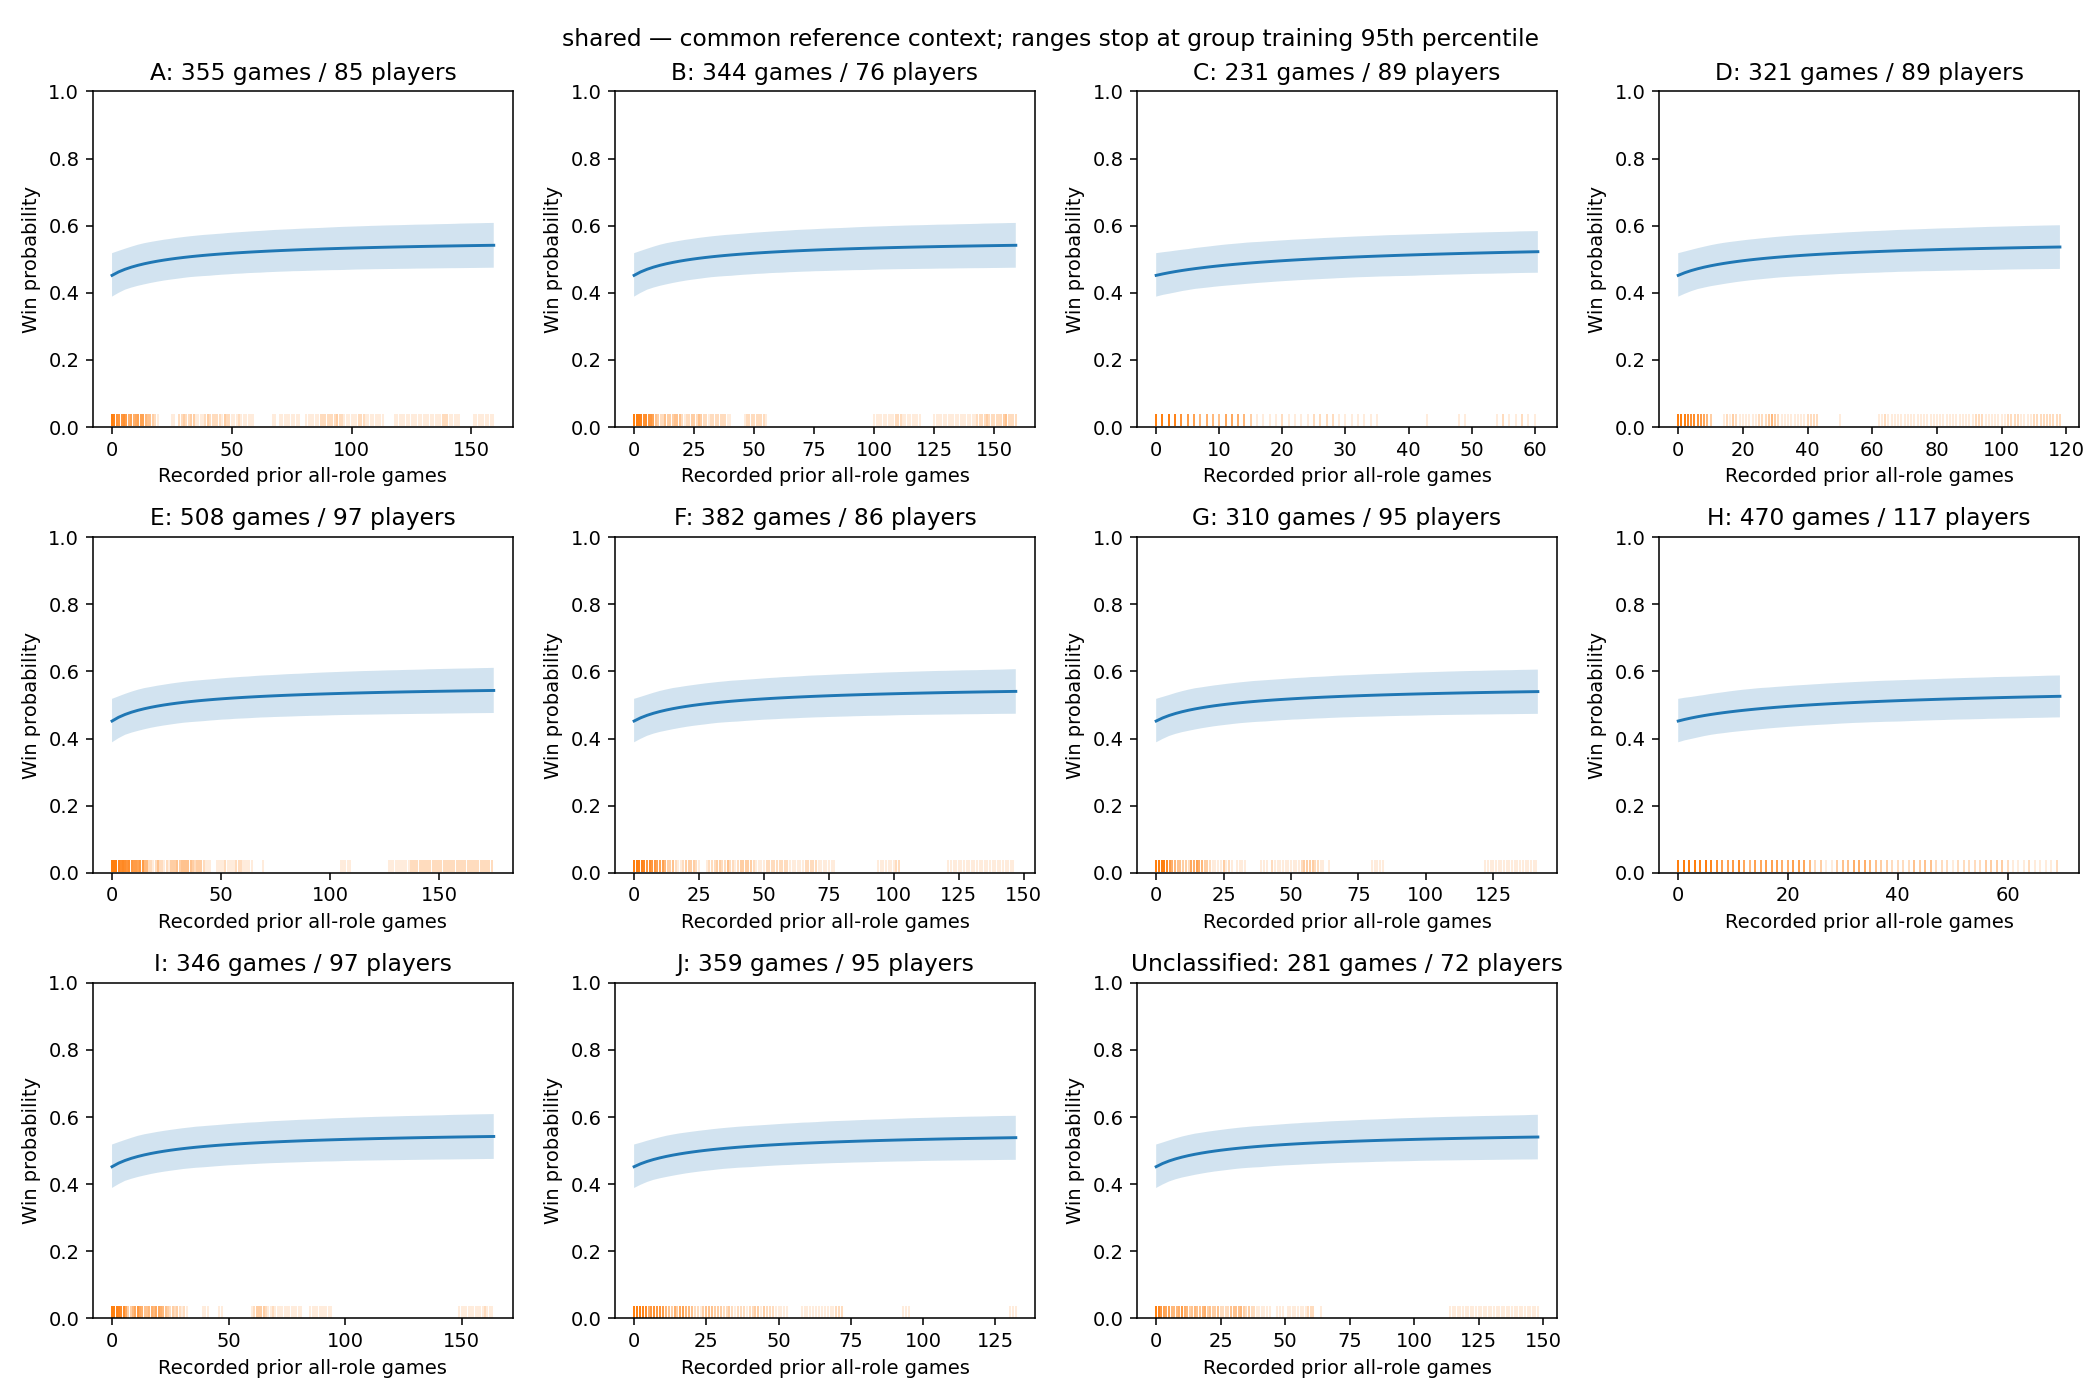

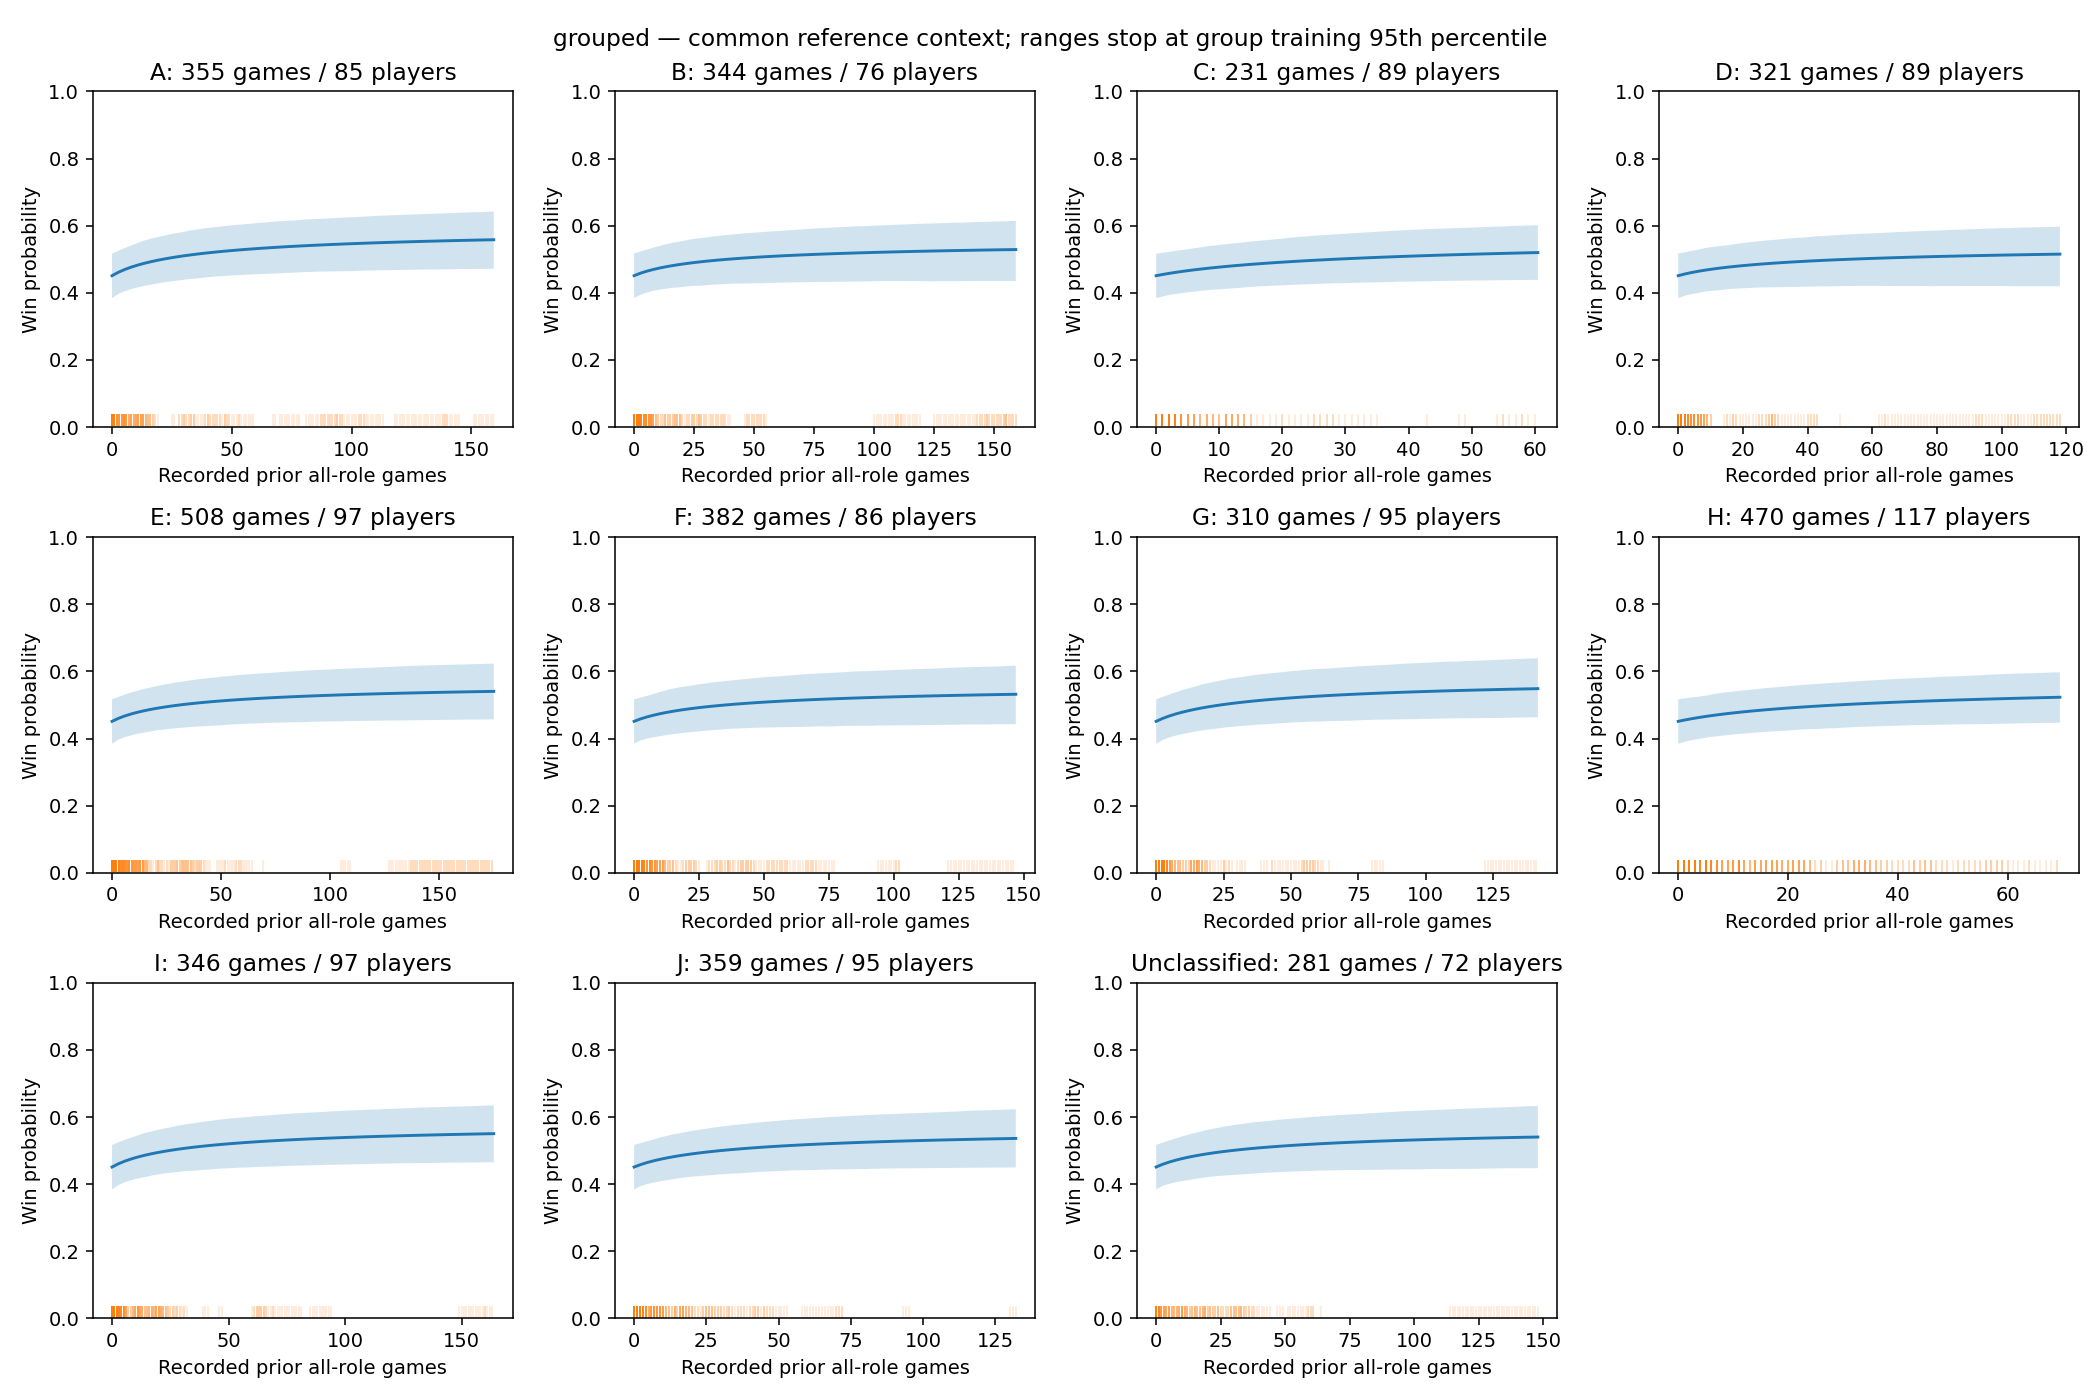

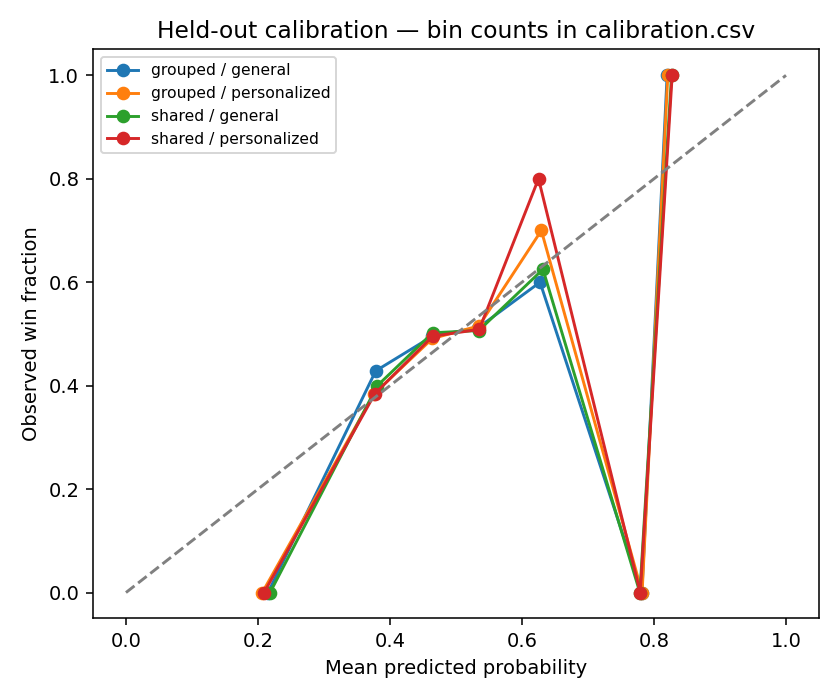

Output version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939
• Recorded prior champion games are season/history-bounded all-role counts, not lifetime experience or mastery points.
• External groups use the workbook's patch 13.7, mostly Gold, EUW/NA/KR study; transport to this cohort is an assumption.
• External gains define groups only and are never added to a predicted probability; J may have a nonzero fitted slope.
• Ranks were checked at collection time, not historically verified for patch 16.19.
• Full-patch matchup rates make this retrospective benchmark-assisted evaluation, not leakage-free prospective prediction.
• Earlier completed held-out games may update saved pregame histories; held-out outcomes never refit parameters.
• General predictions set player and player–champion intercepts to zero; they do not marginalize those effects.
• Unseen player/champion combinations use population 

In [8]:
VALIDATION_DECISION = 'Validation reviewed before final test: identical 852 rows, 147 players, 850 unique matches. Prefer the shared specification by row-weighted validation log loss and Brier in both prediction modes. Reference-player shared/grouped log loss 0.688535431/0.689330255; personalized shared/grouped 0.689121127/0.689884399. Reference-player shared has the lowest validation log loss among the prespecified outputs. Equal-player losses differ only slightly and favor grouped; calibration bins were inspected, with sparse extreme bins limiting interpretation. Personalization did not improve row-weighted validation losses. Retain both original shared/grouped specifications and both reference-player/personalized prediction quantities for final comparison; no tuning, recalibration, added predictors, or model changes. Test outcomes have not been inspected and will not change this decision.'
if RUN_MODELING and CONFIG.profile == 'full' and VALIDATION_DECISION.strip():
    model_results = modeling.finalize_modeling(
        prepared, model_results, OUTPUT_PATH, CONFIG, decision=VALIDATION_DECISION)
    display(model_results['metrics'])
    display(model_results['recommendation_summary'])
    for name in ('shared_group_curves','grouped_group_curves','test_calibration'):
        display(Image(filename=str(OUTPUT_PATH / 'figures' / (name + '.png'))))
else:
    print('Final test, curves and paired recommendations are pending the full fits and written validation decision.')
print('Output version:', OUTPUT_PATH)
for limitation in modeling.LIMITS:
    print('•', limitation)


## 9. Diagnostic and personalization report

Summary changes are descriptive point estimates; individual paired preferences include posterior 95% credible intervals and probabilities. Examples below are selected for the largest personalization shifts and are explicitly illustrative.


In [9]:
if isinstance(model_results, dict) and 'recommendation_summary' in model_results:
    diagnostic_summary = pd.DataFrame([
        dict(model=name, status=r['status'], coordinates=len(r['diagnostics']),
             max_Rhat=r['diagnostics'].rank_split_Rhat.max(),
             min_bulk_ESS=r['diagnostics'].bulk_ESS.min(),
             min_tail_ESS=r['diagnostics'].tail_ESS.min(),
             divergences=sum(c['divergences'] for c in r['chain_info']),
             min_chain_acceptance=min(c['acceptance_rate'] for c in r['chain_info']))
        for name, r in model_results['results'].items()])
    display(diagnostic_summary)
    diagnostic_summary.to_csv(OUTPUT_PATH / 'diagnostic_summary.csv', index=False)
    paired = pd.read_parquet(OUTPUT_PATH / 'paired_recommendations.parquet')
    pair_key = ['model', 'puuid', 'match_id', 'target_row_id', 'reference',
                'reference_champion_id', 'alternative_champion_id']
    reference_player = paired.loc[paired['mode'].eq('general')]
    personalized = paired.loc[paired['mode'].eq('personalized')]
    compared = reference_player.merge(personalized, on=pair_key,
        suffixes=('_reference_player', '_personalized'), validate='one_to_one')
    compared['point_preference_changed'] = (compared.point_prefers_alternative_reference_player
                                           != compared.point_prefers_alternative_personalized)
    compared['personalization_change_pp'] = (compared.difference_pp_personalized
                                            - compared.difference_pp_reference_player)
    personalization_summary = compared.groupby(['model', 'reference']).agg(
        pairs=('target_row_id', 'size'), targets=('target_row_id', 'nunique'),
        players=('puuid', 'nunique'), fraction_point_preference_changed=('point_preference_changed', 'mean'),
        median_change_in_paired_mean_pp=('personalization_change_pp', 'median'),
        reference_player_uncertain=('preference_reference_player', lambda s: s.eq('Uncertain').mean()),
        personalized_uncertain=('preference_personalized', lambda s: s.eq('Uncertain').mean()),
        alternative_sparse_training=('alternative_sparse_training_support_personalized', 'mean')).reset_index()
    display(personalization_summary)
    personalization_summary.to_csv(OUTPUT_PATH / 'personalization_summary.csv', index=False)
    compared.to_parquet(OUTPUT_PATH / 'personalization_comparison.parquet', index=False)
    # Illustrative largest point-estimate changes, explicitly selected for that reason.
    example_keys = compared.loc[compared.groupby(['model', 'reference']).personalization_change_pp
        .apply(lambda s: s.abs().idxmax()), pair_key]
    examples = paired.merge(example_keys, on=pair_key, validate='many_to_one')
    names = {cid: row['riot_name'] for cid, row in modeling.registry.CHAMPIONS.items()}
    examples['reference_champion'] = examples.reference_champion_id.map(names)
    examples['alternative_champion'] = examples.alternative_champion_id.map(names)
    print('Illustrative largest personalization shifts per model/reference; these are selected examples, not typical cases.')
    display(examples[['model', 'mode', 'reference', 'reference_champion', 'alternative_champion',
        'reference_experience', 'alternative_experience', 'reference_group', 'alternative_group',
        'difference_pp', 'low_pp', 'high_pp', 'probability_alternative_higher', 'preference',
        'reference_sparse_training_support', 'alternative_sparse_training_support']])
    examples.to_csv(OUTPUT_PATH / 'illustrative_personalization_examples.csv', index=False)
    print('Each interval and probability concerns the alternative minus its paired reference. Sparse-support flags are descriptive.')
    print('Reference-player identity effects are zero; these predictions are not population averages.')
    print('Curves describe conditional associations. Full-patch external rates make evaluation retrospective benchmark-assisted.')
else:
    print('Substantive reporting requires both converged full fits, validation review and final-test evaluation.')


,model,status,coordinates,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,min_chain_acceptance
0,shared,converged,1871,1.007028,3234.518246,2237.554687,0,1.0
1,grouped,converged,1882,1.006339,2450.239025,2191.764990,0,1.0


,model,reference,pairs,targets,players,fraction_point_preference_changed,median_change_in_paired_mean_pp,reference_player_uncertain,personalized_uncertain,alternative_sparse_training
0,grouped,main,3315,534,108,0.019910,0.014015,0.971041,0.985822,0.954148
1,grouped,played,4003,754,139,0.019485,-0.028359,0.956533,0.982763,0.940295
2,shared,main,3315,534,108,0.023228,0.023099,0.964103,0.985822,0.954148
3,shared,played,4003,754,139,0.020235,-0.016865,0.947789,0.982513,0.940295


Illustrative largest personalization shifts per model/reference; these are selected examples, not typical cases.


,model,mode,reference,reference_champion,alternative_champion,reference_experience,alternative_experience,reference_group,alternative_group,difference_pp,low_pp,high_pp,probability_alternative_higher,preference,reference_sparse_training_support,alternative_sparse_training_support
0,shared,general,played,Akshan,Locke,82,51,F,Unclassified,10.377392,-0.251826,19.503093,0.970625,Uncertain,True,False
1,shared,general,main,Akshan,Locke,82,51,F,Unclassified,10.377392,-0.251826,19.503093,0.970625,Uncertain,True,False
2,shared,personalized,played,Akshan,Locke,82,51,F,Unclassified,8.530799,-4.677505,20.232239,0.911250,Uncertain,True,False
3,shared,personalized,main,Akshan,Locke,82,51,F,Unclassified,8.530799,-4.677505,20.232239,0.911250,Uncertain,True,False
4,grouped,general,played,Akshan,Locke,82,51,F,Unclassified,10.851522,-1.074686,22.511286,0.963542,Uncertain,True,False
5,grouped,general,main,Akshan,Locke,82,51,F,Unclassified,10.851522,-1.074686,22.511286,0.963542,Uncertain,True,False
6,grouped,personalized,played,Akshan,Locke,82,51,F,Unclassified,8.929577,-5.257808,21.987508,0.899375,Uncertain,True,False
7,grouped,personalized,main,Akshan,Locke,82,51,F,Unclassified,8.929577,-5.257808,21.987508,0.899375,Uncertain,True,False


Each interval and probability concerns the alternative minus its paired reference. Sparse-support flags are descriptive.
Reference-player identity effects are zero; these predictions are not population averages.
Curves describe conditional associations. Full-patch external rates make evaluation retrospective benchmark-assisted.


## 10. Running and resuming

First review grouping, Unclassified support, history depths, missingness and splits in [broad_rank_eda.ipynb](broad_rank_eda.ipynb). Run this notebook independently with `RUN_MODELING=False` to prepare and verify inputs. The workbook and cohort source stay pinned.

For an optional small execution check: install the optional backend in your notebook environment, set `profile='smoke'`, set `RUN_MODELING=True`, save, and Run All. This produces a separate smoke version; its small chains are not a convergence or performance result.

For the intended full comparison: restore `profile='full'`, enable the same switch, save, and Run All. Interrupting loses at most the current unfinished chain; reopening and Run All with the same sources/settings/code reuses the preparation version and verified completed chains. Full diagnostics must pass before performance or recommendations are exported. No package installation or collection happens automatically.

## 11. Completed results — 2026-10-28

Preparation, corrected smoke, both full Pyro 1.9.2 NUTS fits, staged validation/final-test evaluation, supported group curves and paired recommendations completed. Original full specifications/settings and pinned inputs were retained. The last grouped chain restarted after the requested pause; all seven earlier chain caches were reused. The modeling test suite passed all 18 tests.

Usable train: **3,907 rows / 265 players / 3,892 matches**; validation: **852 / 147 / 850**; final test: **928 / 152 / 925**. Splits are match-disjoint.

| Model | Worst R-hat | Minimum bulk ESS | Minimum tail ESS | Divergences | Minimum chain acceptance |
|---|---:|---:|---:|---:|---:|
| shared | 1.00703 | 3235 | 2238 | 0 | 1.00 |
| grouped | 1.00634 | 2450 | 2192 | 0 | 1.00 |

Both pass the unchanged full diagnostic gate. Tree-depth saturation and BFMI are unavailable from the wrapper.

| Split | Model | Prediction | Log loss | Brier | AUC | Equal-player log loss |
|---|---|---|---:|---:|---:|---:|
| validation | shared | Reference player | 0.688535 | 0.247793 | 0.549666 | 0.686729 |
| validation | shared | Personalized | 0.689121 | 0.248087 | 0.543858 | 0.686973 |
| validation | grouped | Reference player | 0.689330 | 0.248191 | 0.544475 | 0.686596 |
| validation | grouped | Personalized | 0.689884 | 0.248470 | 0.539620 | 0.686913 |
| test | shared | Reference player | 0.693213 | 0.250042 | 0.518754 | 0.689115 |
| test | shared | Personalized | 0.693234 | 0.250049 | 0.520338 | 0.689232 |
| test | grouped | Reference player | 0.693382 | 0.250119 | 0.517871 | 0.689786 |
| test | grouped | Personalized | 0.693364 | 0.250107 | 0.519869 | 0.689841 |

**Decision and predictive result.** Validation favored shared on row-weighted log loss/Brier in both modes; this decision and the unchanged specifications were recorded before test. Grouped did not improve final-test log loss/Brier; test discrimination was weak (AUC about .518–.520). Equal-player validation losses slightly favored grouped; test equal-player losses favored shared. Calibration is recorded by bin and plotted above; most probabilities lie between .4 and .6, while extreme bins contain very few rows and cannot support strong calibration conclusions.

**Personalization and recommendations.** For shared, personalization changed point preferences in 2.02% of 4,003 played-pick comparisons (754 targets, 139 players), and 2.32% of 3,315 recorded-main comparisons (534 targets, 108 players). Their personalized paired intervals include zero in 98.25% and 98.58% of cases, respectively. Alternatives have sparse likelihood-training support in 94.03%/95.41% of these comparisons under the reported flags; season-history experience and likelihood-training support are distinct. Personalization did not improve validation or final-test loss for shared. Grouped showed similarly small point-preference changes and predominantly uncertain comparisons.

Illustrative largest shared-model personalization shift: Akshan (82 recorded games) versus Locke (51), with an 18.33 pp better raw matchup for Locke. The alternative-minus-reference modeled difference is **+10.38 pp [−0.25, +19.50]**, P(alternative higher)=**.9706**, for the reference player, versus **+8.53 pp [−4.68, +20.23]**, P=**.9113**, personalized. Both remain uncertain by the 95% interval rule; the reference choice has sparse training support. This deliberately selected example is not typical. Each choice uses its own recorded history, group and benchmark; no alternative receives an observed outcome.

**Curves and limits.** Group curves show conditional associations with broad overlapping uncertainty; there is no imposed A–J ordering, and the grouped specification did not improve prediction. Reference-player predictions set player and player–champion effects to zero and are not population averages. Parameters/identity effects stayed frozen in held-out evaluation; only saved pregame histories may expand after earlier games finish. This is retrospective benchmark-assisted evaluation because the external rates cover the full patch. The results do not establish causal practice gains or benefits of switching. External benchmark/transport uncertainty is outside the posterior intervals.

All model fits, metrics, calibration bins, pair-level 95% intervals/probabilities, training-support flags and curves are retained in version `20261028T193830350096Z_5a469939`. No execution blocker remains.


## 12. What the saved posteriors learned about experience and matchup

This section runs independently using **only the completed full-fit version** `20261028T193830350096Z_5a469939`. It verifies manifests, diagnostic gates and chain hashes **before loading samples**. It does not call fitting, model selection or held-out scoring. Earlier notebook outputs are retained.

Both models sampled stably, but final-test AUC was only about .518–.520, A–J grouping did not improve predictive losses, and personalized preferences were mostly uncertain. Posterior associations must be read in that context.

In [2]:
from pathlib import Path
import inspect, json
import numpy as np
import pandas as pd
from IPython.display import display
from hlr_model import broad_rank_modeling as modeling

INTERPRET_PATH = Path(modeling.__file__).resolve().parent / 'data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939'
preparation = json.loads((INTERPRET_PATH / 'preparation_manifest.json').read_text())
identity = json.loads(preparation['identity'])
assert modeling.sha(Path(modeling.__file__).read_bytes()) == identity['helper_sha256']
assert all(modeling.sha((INTERPRET_PATH / name).read_bytes()) == h
           for name, h in preparation['output_sha256'].items())
artifact_hashes = json.loads((INTERPRET_PATH / 'final_artifact_manifest.json').read_text())['sha256']
fit_manifests = {}
for name in ('shared', 'grouped'):
    folder = INTERPRET_PATH / 'fits' / name
    for file in ['fit_manifest.json', 'fit_status.json', 'sampling_diagnostics.csv',
                 *[f'chain_{i}.json' for i in range(4)]]:
        assert modeling.sha((folder / file).read_bytes()) == artifact_hashes[str((folder / file).relative_to(INTERPRET_PATH))]
    manifest = json.loads((folder / 'fit_manifest.json').read_text())
    status = json.loads((folder / 'fit_status.json').read_text())
    diagnostic = pd.read_csv(folder / 'sampling_diagnostics.csv')
    assert manifest['model'] == name and manifest['backend_version'] == '1.9.2'
    assert manifest['sampling'] == dict(chains=4, draws=1200, warmup=600, max_tree_depth=9, train_match_limit=None)
    assert manifest['target_accept'] == .9 and manifest['torch_threads'] == 1
    assert manifest['model_source_sha256'] == modeling.sha(inspect.getsource(modeling.pyro_model).encode())
    assert manifest['sampler_source_sha256'] == modeling.sha(inspect.getsource(modeling.fit_one).encode())
    assert status['status'] == 'converged' and status['diagnostic_gate_passed']
    assert status['thresholds'] == dict(max_rhat=1.01, min_bulk_tail_ess=400, max_divergences=0, min_acceptance=.8)
    assert np.isfinite(diagnostic[['rank_split_Rhat', 'bulk_ESS', 'tail_ESS']]).all().all()
    assert diagnostic.rank_split_Rhat.max() < 1.01 and diagnostic.bulk_ESS.min() > 400 and diagnostic.tail_ESS.min() > 400
    assert len(status['chains']) == 4
    for i in range(4):
        info = json.loads((folder / f'chain_{i}.json').read_text())
        assert info == status['chains'][i] and info['chain'] == i
        assert info['divergences'] == 0 and info['acceptance_rate'] >= .8
        assert modeling.sha((folder / f'chain_{i}.npz').read_bytes()) == info['samples_sha256']
    fit_manifests[name] = manifest
# Both fits are verified before any sample archive is opened.
played_interpret = pd.read_parquet(INTERPRET_PATH / 'prepared_played.parquet')
training_interpret = played_interpret.loc[played_interpret.split.eq('train') & played_interpret.usable_data].copy()
interpret_design = modeling.Design(training_interpret)
for manifest in fit_manifests.values():
    assert modeling.sha(training_interpret.to_json(orient='split', index=False).encode()) == manifest['training_sha256']
    assert json.loads(modeling.canonical(interpret_design.metadata())) == manifest['design']
assert fit_manifests['shared']['design'] == fit_manifests['grouped']['design']
# No numeric basis was serialized separately. Recover its exact fit-time definition
# from the hash-verified Design implementation and the saved group ordering.
assert tuple(fit_manifests['grouped']['design']['groups']) == modeling.GROUPS
basis_interpret = interpret_design.group_basis
np.testing.assert_allclose(basis_interpret.sum(axis=0), 0, atol=1e-14)
np.testing.assert_allclose(basis_interpret.T @ basis_interpret, np.eye(len(modeling.GROUPS)-1), atol=1e-14)
posterior_interpret = {}
for name in ('shared', 'grouped'):
    chains = []
    for i in range(4):
        with np.load(INTERPRET_PATH / 'fits' / name / f'chain_{i}.npz') as archive:
            chain = {k: archive[k] for k in archive.files}
        assert all(v.shape[0] == 1200 and np.isfinite(v).all() for v in chain.values())
        chains.append(chain)
    posterior_interpret[name] = modeling.flatten_draws({'samples': {
        k: np.stack([chain[k] for chain in chains]) for k in chains[0]}})
print('Verified full-fit provenance, unchanged diagnostic gates and 4,800 draws per model; no fitting or scoring called.')
print('Saved raw matchup mean / training SD:', interpret_design.mean[0], interpret_design.scale[0])


Verified full-fit provenance, unchanged diagnostic gates and 4,800 draws per model; no fitting or scoring called.
Saved raw matchup mean / training SD: 0.501680342974149 0.05739845497765121


**Units and parameters.** The raw matchup coefficient is a log-odds change for **one training SD of raw matchup probability: 0.05739845, or 5.739845 percentage points** (saved training mean .50168034). It is an estimated coefficient, not an offset or a direct win-probability change. Experience enters as `b × n/(n+k)`, where `b` is the asymptotic **log-odds amplitude** and `k` is the recorded-game count at half that amplitude. In the grouped model, the common amplitude is the unweighted mean across its 11 zero-sum groups; each group's actual total is reconstructed below.

The identity and group scales are reported after exponentiating their log parameters. They are on the **log-odds scale**. Champion/group scales govern orthonormal zero-sum contrasts; a level's marginal prior SD conditional on its scale is `sigma × sqrt(1−1/L)`, with L levels. `k` and all scales are positive by construction, so a positive-sign probability would be uninformative; those cells are blank. Sign probabilities for coefficients are fractions of the saved posterior draws, not claims of certainty.

In [3]:
def posterior_row(label, values, *, sign=True, **extra):
    low, median, high = np.quantile(values, [.025, .5, .975])
    return dict(quantity=label, median=median, low_95=low, high_95=high,
                probability_positive=np.mean(values > 0) if sign else np.nan, **extra)

quantity_rows = []
for name, draws in posterior_interpret.items():
    quantities = [('Raw matchup coefficient / training SD', draws['beta'][:, 0], True),
                  ('Shared experience amplitude', draws['beta_exp'], True),
                  ('k (recorded games)', np.exp(draws['log_k']), False),
                  ('Player SD', np.exp(draws['log_sigma_player']), False),
                  ('Player–champion SD', np.exp(draws['log_sigma_pc']), False),
                  ('Champion contrast SD', np.exp(draws['log_sigma_champion']), False)]
    if name == 'grouped':
        quantities.append(('Group-deviation contrast SD', np.exp(draws['log_sigma_group']), False))
    quantity_rows.extend(posterior_row(label, values, sign=sign, model=name) for label, values, sign in quantities)
quantity_table = pd.DataFrame(quantity_rows).set_index(['model', 'quantity'])
display(quantity_table.style.format(precision=3, na_rep='—').format({'probability_positive':'{:.4f}'}, na_rep='—'))

group_draws = posterior_interpret['grouped']
group_deviations = np.exp(group_draws['log_sigma_group'])[:, None] * (group_draws['group_free'] @ basis_interpret.T)
np.testing.assert_allclose(group_deviations.sum(axis=1), 0, atol=1e-12)
group_amplitudes = group_draws['beta_exp'][:, None] + group_deviations
group_rows = []
for j, group in enumerate(modeling.GROUPS):
    support = training_interpret.loc[training_interpret.mastery_group.eq(group)]
    group_rows.append(posterior_row(group, group_amplitudes[:, j],
        training_games=len(support), training_players=support.puuid.nunique(),
        players_with_n_ge_100=support.loc[support.n_recorded.ge(100)].puuid.nunique()))
display(pd.DataFrame(group_rows).rename(columns={'quantity':'group total amplitude'}).set_index('group total amplitude')
        .style.format({'median':'{:.3f}', 'low_95':'{:.3f}', 'high_95':'{:.3f}', 'probability_positive':'{:.4f}'}))
# Formal paired contrasts use the same posterior draw for both groups.
group_pair_rows = []
for i, left in enumerate(modeling.GROUPS):
    for j in range(i+1, len(modeling.GROUPS)):
        group_pair_rows.append(posterior_row(left+' − '+modeling.GROUPS[j], group_amplitudes[:, i]-group_amplitudes[:, j]))
group_pairs_interpret = pd.DataFrame(group_pair_rows)
display(group_pairs_interpret.loc[group_pairs_interpret.quantity.eq('A − J')].set_index('quantity').style.format(precision=3))
print('Paired group comparisons whose unadjusted 95% interval excludes zero:',
      int(((group_pairs_interpret.low_95 > 0) | (group_pairs_interpret.high_95 < 0)).sum()), 'of 55')

print('Posterior correlation between log(k) and common amplitude:',
      {name: round(float(np.corrcoef(draws['log_k'], draws['beta_exp'])[0,1]), 3)
       for name, draws in posterior_interpret.items()})


,median,low_95,high_95,probability_positive,training_games,training_players,players_with_n_ge_100
group total amplitude,,,,,,,
A,0.555,0.182,1.136,0.9977,355,85,6
B,0.407,-0.021,0.914,0.9715,344,76,7
C,0.474,0.025,1.091,0.9794,231,89,2
D,0.365,-0.095,0.922,0.9413,321,89,6
E,0.458,0.092,0.966,0.9929,508,97,3
F,0.432,0.040,0.960,0.9838,382,86,4
G,0.513,0.128,1.111,0.9946,310,95,2
H,0.472,0.079,1.076,0.9904,470,117,2
I,0.512,0.117,1.084,0.9942,346,97,2


,median,low_95,high_95,probability_positive
quantity,,,,
A − J,0.077,-0.331,0.610,0.671


Paired group comparisons whose unadjusted 95% interval excludes zero: 0 of 55
Posterior correlation between log(k) and common amplitude: {'shared': 0.425, 'grouped': 0.493}


**Read the saved curves** shown earlier, or open the existing [shared figure](data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939/figures/shared_group_curves.png) and [grouped figure](data/analyses/broad_rank_mastery_v1/20261028T193830350096Z_5a469939/figures/grouped_group_curves.png). Both common amplitudes are clearly positive conditional on historical champion WR, total games, matchup and the remaining covariates. Their medians are .443 and .466 log-odds; P(positive) is .9992/.9996. Most group totals favor a positive association, while B and D retain negative values within their 95% intervals. There is no guaranteed workbook ordering: **A minus J = .077 [−.331, .610] log-odds, P(A>J)=.671**, and none of the 55 paired group intervals excludes zero. This conclusion uses paired differences, not overlap of marginal intervals.

The half-saturation count is **29 [8, 135] games** for shared and **38 [9, 225]** for grouped. Early saturation versus a slower rise remains poorly identified; the asymptote and k trade off. Many plotted groups have 72–117 training players overall, but just **1–7 distinct players at n≥100**. High-count observations from a few players do not provide broad player support for a learning curve. The curves stop at the existing support/context caps.

These curves are **conditional associations**, holding historical champion WR and the other covariates fixed. They do not measure the total causal benefit of practice; recorded counts are bounded season histories, and the workbook groups are external labels.

In [4]:
# Conditional reference slice: same zero champion/player/player–champion baselines
# as curve_outputs; Bronze/top, 175 total prior games (training median), historical
# champion Beta(1,1) WR .50. Even champion counts allow that WR to remain feasible.
# A and J illustrate the workbook endpoints, chosen by their labels, not fitted ranks.
context_interpret = dict(rank='BRONZE', role='top', total_games=175, historical_wr=.50,
                         raw_matchup=.50, improved_raw_matchup=.52)
assert np.isclose(np.expm1(training_interpret.log_total.median()), 175)
assert training_interpret.matchup_probability.quantile(.25) <= .50 < .52 <= training_interpret.matchup_probability.quantile(.75)
context_x = (np.array([.50, np.log1p(175), .50])-interpret_design.mean)/interpret_design.scale

def reference_probability(draws, amplitude, n, raw_matchup=.50):
    eta = (draws['alpha'] + draws['beta'] @ context_x
           + draws['beta'][:, 0] * (raw_matchup-.50)/interpret_design.scale[0]
           + amplitude*n/(n+np.exp(draws['log_k'])))
    return modeling.expit(eta)

def paired_interval(values):
    low, median, high = np.quantile(values, [.025, .5, .975])
    return f'{median:.2f} [{low:.2f}, {high:.2f}]'

illustrations = []
for name, draws in posterior_interpret.items():
    for group in (['All'] if name == 'shared' else ['A', 'J']):
        support = training_interpret if group == 'All' else training_interpret.loc[training_interpret.mastery_group.eq(group)]
        amplitude = draws['beta_exp'] if group == 'All' else group_amplitudes[:, modeling.GROUPS.index(group)]
        contrasts = [(0,20), (20,50), (50,100)] if group == 'All' else [(0,20), (20,50)]
        for low, high in contrasts:
            assert 0 <= low < high <= min(175, support.n_recorded.quantile(.95))
            endpoint_support = [support.loc[support.n_recorded.between(max(0,n-5), n+5)].puuid.nunique() for n in (low,high)]
            assert min(endpoint_support) >= 3  # descriptive support check, not a change to fitted inference
            p0 = reference_probability(draws, amplitude, low)
            experience_delta = 100*(reference_probability(draws, amplitude, high)-p0)
            matchup_delta = 100*(reference_probability(draws, amplitude, low, .52)-p0)
            net = experience_delta-matchup_delta  # paired within draw; never subtract interval endpoints
            illustrations.append(dict(model=name, group=group, experience=f'{low} → {high}',
                experience_gain_pp=paired_interval(experience_delta), matchup_gain_pp=paired_interval(matchup_delta),
                experience_minus_matchup_pp=paired_interval(net), probability_experience_larger=np.mean(net>0),
                nearby_training_players=f'{endpoint_support[0]} / {endpoint_support[1]}'))
print('Reference context:', context_interpret, '; all champion/player/PC baselines zero (not population averages).')
print('Matchup change .50 → .52 lies inside the training IQR:',
      training_interpret.matchup_probability.quantile([.25,.75]).round(4).to_list())
print('Medians [paired 95% credible intervals] in win-probability percentage points; matchup is improved at the LOWER experience count.')
display(pd.DataFrame(illustrations).set_index(['model','group','experience'])
        .style.format({'probability_experience_larger':'{:.3f}'}))


Reference context: {'rank': 'BRONZE', 'role': 'top', 'total_games': 175, 'historical_wr': 0.5, 'raw_matchup': 0.5, 'improved_raw_matchup': 0.52} ; all champion/player/PC baselines zero (not population averages).
Matchup change .50 → .52 lies inside the training IQR: [0.4792, 0.5278]
Medians [paired 95% credible intervals] in win-probability percentage points; matchup is improved at the LOWER experience count.


**What that probability comparison permits.** For shared, 0→20 recorded games corresponds to **+4.20 pp [1.31, 8.25]**, 20→50 to **+2.24 pp [.79, 3.73]**, and 50→100 to **+1.46 pp [.40, 3.11]**, in this reference slice. A raw matchup improvement from 50% to 52% corresponds to about **+1.50 modeled pp**, not automatically +2 pp. These are paired posterior predictions; their common coefficient/k uncertainty is retained. For example, the 20→50 experience contrast minus that matchup contrast is **+.74 pp [−.81, 2.36]**, with P(experience contrast larger)=.816.

All displayed experience-minus-matchup intervals include zero. These supported illustrations therefore do **not** identify a defensible crossover or a “practice X games to offset Y matchup points” rule. Endpoint support counts use ±5 recorded-game neighborhoods and are **marginal training support**, not proof that the entire fixed covariate combination is densely observed. J near n=50 has only three players; its n≈100 neighborhood has one, so that higher J contrast is omitted. The reference uses 175 prior total games, and every illustrated champion count is ≤100; no count exceeds its support cap. Holding champion baseline and historical WR fixed isolates the model terms and does not represent an actual champion switch.

In [5]:
pc_likelihood_counts = training_interpret.groupby(['puuid','model_champion_id']).size()
print(f'Likelihood support: {len(pc_likelihood_counts):,} player–champion pairs; '
      f'median {pc_likelihood_counts.median():.0f} game; '
      f'{pc_likelihood_counts.eq(1).mean():.1%} one-game pairs; '
      f'{pc_likelihood_counts.lt(5).mean():.1%} with fewer than 5 games.')
print(f'Recorded history is different: played-row median {training_interpret.n_recorded.median():.0f} prior champion games, '
      f'95th percentile {training_interpret.n_recorded.quantile(.95):.1f}.')
personalization_saved = pd.read_csv(INTERPRET_PATH / 'personalization_summary.csv')
paired_saved = pd.read_parquet(INTERPRET_PATH / 'paired_recommendations.parquet')
personal_rows = []
for row in personalization_saved.itertuples():
    block = paired_saved.loc[paired_saved.model.eq(row.model) & paired_saved.reference.eq(row.reference)]
    ref = block.loc[block['mode'].eq('general')]
    per = block.loc[block['mode'].eq('personalized')]
    personal_rows.append(dict(model=row.model, reference=row.reference,
        point_preference_changed=row.fraction_point_preference_changed,
        personalized_interval_contains_zero=row.personalized_uncertain,
        alternative_pc_absent_from_likelihood=1-per.alternative_pc_training_supported.mean(),
        alternative_sparse_training=row.alternative_sparse_training,
        reference_median_interval_width_pp=(ref.high_pp-ref.low_pp).median(),
        personalized_median_interval_width_pp=(per.high_pp-per.low_pp).median()))
display(pd.DataFrame(personal_rows).set_index(['model','reference']).style.format({
    'point_preference_changed':'{:.1%}', 'personalized_interval_contains_zero':'{:.1%}',
    'alternative_pc_absent_from_likelihood':'{:.1%}', 'alternative_sparse_training':'{:.1%}',
    'reference_median_interval_width_pp':'{:.1f}', 'personalized_median_interval_width_pp':'{:.1f}'}))


Likelihood support: 1,417 player–champion pairs; median 1 game; 59.4% one-game pairs; 87.8% with fewer than 5 games.
Recorded history is different: played-row median 11 prior champion games, 95th percentile 155.7.


**Why personalization remained uncertain.** The fitted player and player–champion SD medians are about **.10–.11 log-odds**, with substantial scale uncertainty (see the first table). Fitted effects are partially pooled: few likelihood observations leave many player–champion effects close to zero in posterior mean and poorly known individually. Recorded season-history games supply pregame counts/WR; they are **not all training Bernoulli observations** for that identity. In played-pick comparisons, about 65% of alternatives have no fitted player–champion identity at all; their effects are drawn from the fitted population distribution with uncertainty. Existing comparisons confirm small mean changes and wide intervals rather than assuming this explanation from the priors alone.

A player's common intercept cancels in a same-player **logit difference**, so it cannot by itself reverse a within-player ranking; it can still change a probability difference's magnitude through the logistic link. Player–champion deviations can change rankings, but weak support and shrinkage limit point changes while identity uncertainty widens paired intervals. Champion-baseline/coefficient uncertainty already contributes to the reference-player intervals; personalization is not their sole source. Sparse-support flags are descriptive, using the existing <5 player–champion games / <20 champion games / <5 group players definitions.

**What we can tell David:** experience and stronger raw matchups both have positive fitted conditional associations. Returns appear to saturate, but the number of games setting that bend is uncertain. The data do not resolve a useful A–J ordering, a reliable experience–matchup threshold, or confident individualized switching advice. Stable sampling supports interpretation of this fitted posterior; it does not turn weak held-out discrimination into a useful decision rule. These remain retrospective benchmark-assisted findings with fixed full-patch external rates, not causal evidence that practice or switching improves wins.